# Exploratory Data Analysis – WanderScape Travel Dataset

## Introduction

This project focuses on performing Exploratory Data Analysis (EDA) on the WanderScape Travel Dataset to understand tourist demographics, travel preferences, trip characteristics, costs, satisfaction levels, and revenue patterns.

The analysis uses Python and popular data analysis and visualization libraries to clean, explore, summarize, and visualize the dataset. Various statistical techniques and visualizations are used to identify patterns, trends, relationships, and potential insights within the data.

The key areas explored in this analysis include:

- Tourist demographics such as age, gender, and nationality
- Travel groups, trip types, and travel purposes
- Destination and travel-season preferences
- Transport modes and travel duration
- Hotel, transportation, and overall trip costs
- Customer satisfaction
- Booking and revenue patterns

The objective of this EDA is to transform the raw travel data into meaningful insights that can help understand customer behavior and travel trends, while also providing a strong foundation for further analysis and business decision-making.

## 1. Environment & Library Setup

The analysis uses Pandas for data manipulation, NumPy for numerical operations, and Matplotlib for data visualization.

In [24]:
# Data manipulation and analysis
import pandas as pd

# Numerical operations
import numpy as np

# Data visualization
import matplotlib.pyplot as plt

# Apply a consistent plotting style
plt.style.use("bmh")

## 2. Load the Dataset

The validated WanderScape travel dataset generated in the previous Python workflow is loaded into a Pandas DataFrame for exploratory analysis.

In [25]:
# Load the validated WanderScape travel dataset
df = pd.read_csv("WanderScape_Travel_Dataset.csv")

## 3. Initial Data Inspection

The dataset is initially inspected to understand its structure, dimensions, data types, completeness, uniqueness, and descriptive statistics before beginning exploratory analysis.

In [26]:
df.head()

,Booking_ID,Booking_Date,Travel_Date,Return_Date,Tourist_ID,Age,Gender,Nationality,Travel_Group,Trip_Type,...,Transport_Cost,Hotel_Cost,Food_Cost,Shopping_Cost,Local_Transport_Cost,Activities_Cost,Travel_Purpose,Travel_Season,Satisfaction_Rating,Total_Trip_Cost
0,BK000001,16-08-2025,06-09-2025,11-09-2025,T770487,40,Male,South Africa,Solo,Domestic,...,23390.0,14015.0,12647.0,12740.0,5214.0,8873.0,Adventure,Spring,4.0,76879.0
1,BK000002,01-01-2025,06-03-2025,11-03-2025,T331148,42,Female,India,Solo,International,...,7423.0,32911.0,9927.0,5590.0,4000.0,3691.0,Leisure,Summer,4.8,63542.0
2,BK000003,02-11-2024,16-12-2024,24-12-2024,T678856,32,Female,USA,Family,Domestic,...,33260.0,36783.0,10465.0,24210.0,5724.0,26597.0,Honeymoon,Summer,4.6,137039.0
3,BK000004,17-08-2025,14-11-2025,18-11-2025,T816751,53,Male,USA,Solo,International,...,16336.0,22145.0,6786.0,3668.0,2628.0,17360.0,Adventure,Summer,4.2,68923.0
4,BK000005,17-04-2025,03-06-2025,11-06-2025,T694731,29,Male,Spain,Couple,International,...,10532.0,25696.0,10485.0,4478.0,7091.0,3171.0,Family Vacation,Summer,4.3,61453.0


In [27]:
# Check the number of records and variables
print(f"Rows : {df.shape[0]}")
print(f"Columns : {df.shape[1]}")

Rows : 20000
Columns : 29


In [28]:
# Review column data types and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Booking_ID             20000 non-null  str    
 1   Booking_Date           20000 non-null  str    
 2   Travel_Date            20000 non-null  str    
 3   Return_Date            20000 non-null  str    
 4   Tourist_ID             20000 non-null  str    
 5   Age                    20000 non-null  int64  
 6   Gender                 20000 non-null  str    
 7   Nationality            20000 non-null  str    
 8   Travel_Group           20000 non-null  str    
 9   Trip_Type              20000 non-null  str    
 10  Continent              20000 non-null  str    
 11  Country                20000 non-null  str    
 12  City                   20000 non-null  str    
 13  Destination_Type       20000 non-null  str    
 14  Transport_Mode         20000 non-null  str    
 15  Travel_Durati

In [29]:
# Check for missing values across all columns
df.isnull().sum()

Booking_ID               0
Booking_Date             0
Travel_Date              0
Return_Date              0
Tourist_ID               0
Age                      0
Gender                   0
Nationality              0
Travel_Group             0
Trip_Type                0
Continent                0
Country                  0
City                     0
Destination_Type         0
Transport_Mode           0
Travel_Duration_Hours    0
Hotel_Category           0
Hotel_Rating             0
Stay_Days                0
Transport_Cost           0
Hotel_Cost               0
Food_Cost                0
Shopping_Cost            0
Local_Transport_Cost     0
Activities_Cost          0
Travel_Purpose           0
Travel_Season            0
Satisfaction_Rating      0
Total_Trip_Cost          0
dtype: int64

In [30]:
# Check for duplicate records
print("Duplicate Rows :", df.duplicated().sum())

Duplicate Rows : 0


In [31]:
# Generate descriptive statistics for numerical variables
df.describe()

,Age,Travel_Duration_Hours,Hotel_Rating,Stay_Days,Transport_Cost,Hotel_Cost,Food_Cost,Shopping_Cost,Local_Transport_Cost,Activities_Cost,Satisfaction_Rating,Total_Trip_Cost
count,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.00000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000
mean,34.973150,13.713120,4.273145,5.272750,19831.766300,23607.29095,8378.409050,10337.900200,4257.020800,10684.109500,4.264510,77096.496800
std,11.175763,21.296895,0.373918,1.805054,9705.378914,10570.01573,4138.106927,5887.694722,2300.341431,5709.128707,0.437427,24418.606316
min,18.000000,2.000000,3.500000,2.000000,5006.000000,7500.00000,2000.000000,1251.000000,750.000000,2005.000000,3.000000,24913.000000
25%,26.000000,4.900000,4.000000,4.000000,12251.250000,15419.50000,5116.750000,5645.000000,2433.000000,6159.000000,4.000000,60682.750000
50%,35.000000,7.700000,4.300000,5.000000,18780.000000,22414.00000,7925.000000,9855.000000,4026.000000,10094.000000,4.300000,71678.500000
75%,43.000000,10.700000,4.600000,7.000000,25629.250000,29577.50000,10840.250000,13971.250000,5661.250000,14159.000000,4.600000,86494.000000
max,70.000000,120.000000,5.000000,10.000000,52499.000000,59953.00000,22499.000000,29982.000000,12000.000000,29982.000000,5.000000,189161.000000


## 4. Data Preparation

The date fields are converted to Pandas datetime format to enable time-based analysis and extraction of calendar components such as booking month.

In [35]:
# Convert date columns from DD-MM-YYYY strings to datetime format
df["Booking_Date"] = pd.to_datetime(
    df["Booking_Date"],
    format="%d-%m-%Y"
)

df["Travel_Date"] = pd.to_datetime(
    df["Travel_Date"],
    format="%d-%m-%Y"
)

df["Return_Date"] = pd.to_datetime(
    df["Return_Date"],
    format="%d-%m-%Y"
)

In [39]:
# Extract the booking month for monthly trend analysis
df["Booking_Month"] = df["Booking_Date"].dt.month_name()

## 5. Exploratory Analysis

This section explores key booking, customer, destination, travel, accommodation, and satisfaction dimensions within the WanderScape dataset.

### 5.1 Monthly Bookings Trend

Monthly booking volumes are analyzed to identify seasonal patterns and variations in booking activity throughout the year.

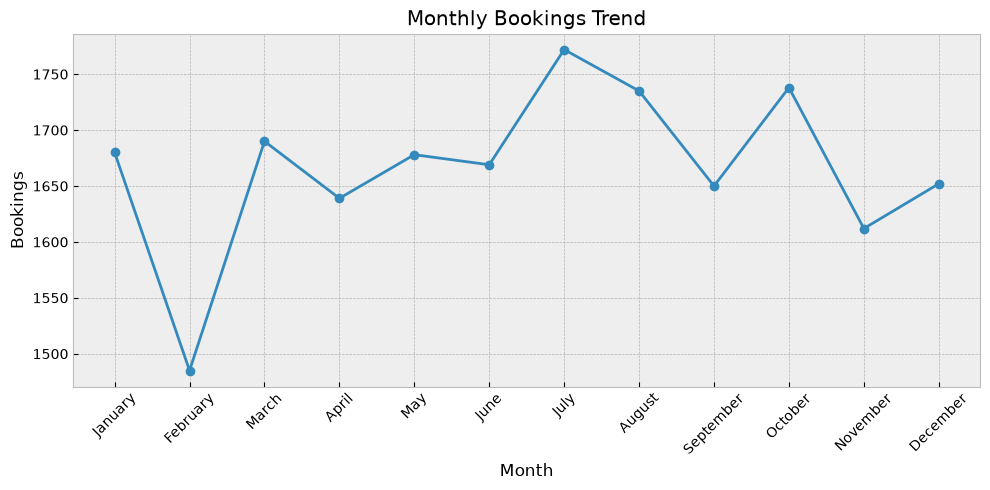

In [ ]:
# Calculate total bookings for each calendar month
monthly = (
    df.groupby("Booking_Month")
      .size()
      .reindex([
          "January","February","March","April","May","June",
          "July","August","September","October","November","December"
      ])
)

plt.figure(figsize=(10,5))

plt.plot(
    monthly.index,
    monthly.values,
    marker="o",
    linewidth=2
)

plt.title("Monthly Bookings Trend")
plt.xlabel("Month")
plt.ylabel("Bookings")

plt.xticks(rotation=45)

plt.tight_layout()

plt.savefig("01_Monthly_Bookings_Trend.png")

plt.show()

### 5.2 Revenue by Country

Revenue contribution is analyzed at the country level to identify the destinations generating the highest total trip value.

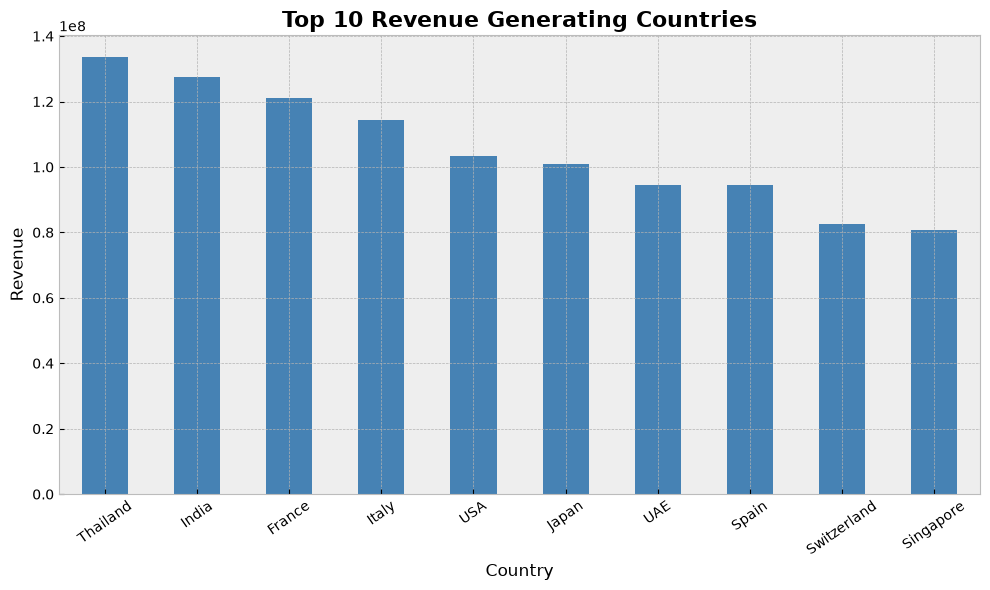

In [ ]:
# Calculate total trip revenue by country and identify the top 10
country_revenue = (
    df.groupby("Country")["Total_Trip_Cost"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

plt.figure(figsize=(10,6))

country_revenue.plot(
    kind="bar",
    color="steelblue"
)

plt.title("Top 10 Revenue Generating Countries", fontsize=16, fontweight="bold")
plt.xlabel("Country")
plt.ylabel("Revenue")

plt.xticks(rotation=35)

plt.tight_layout()

plt.savefig("02_Revenue_By_Country.png", dpi=300)

plt.show()

### 5.3 Destination Type Distribution

The distribution of destination types is examined to understand which categories attract the highest proportion of travel bookings.

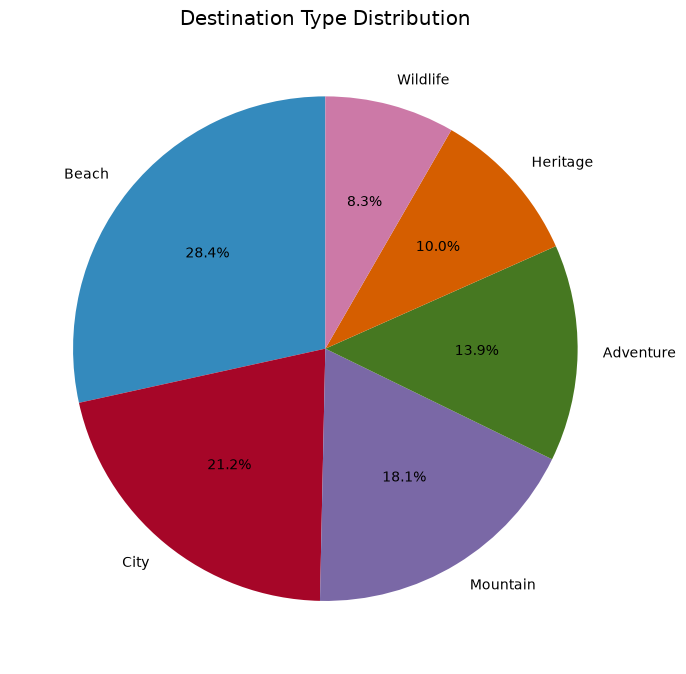

In [ ]:
# Count bookings across destination categories
destination = df["Destination_Type"].value_counts()

plt.figure(figsize=(7,7))

plt.pie(
    destination,
    labels=destination.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Destination Type Distribution")

plt.tight_layout()

plt.savefig("03_Destination_Type_Distribution.png")

plt.show()

### 5.4 Tourist Age Distribution

The age distribution of travelers is examined to understand the demographic profile represented in the dataset.

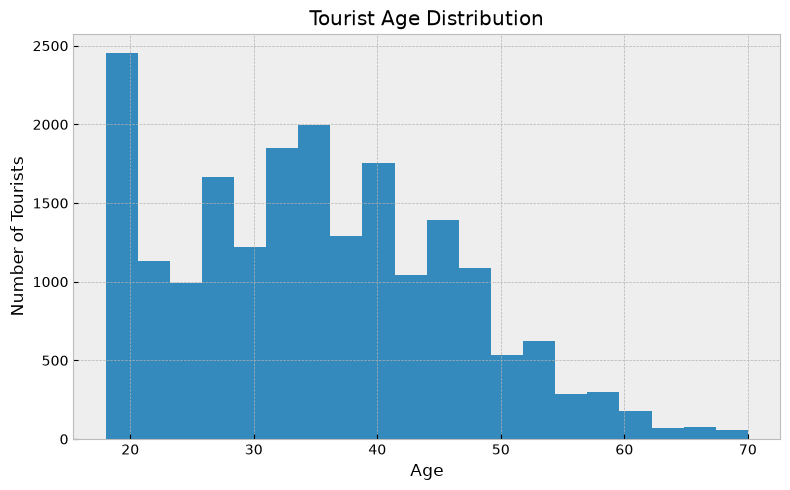

In [ ]:
# Visualize the distribution of traveler ages
plt.figure(figsize=(8,5))

plt.hist(
    df["Age"],
    bins=20
)

plt.title("Tourist Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Tourists")

plt.tight_layout()

plt.savefig("04_Tourist_Age_Distribution.png")

plt.show()

### 5.5 Travel Purpose Distribution

Travel purpose is analyzed to understand the primary reasons for travel represented across the booking dataset.

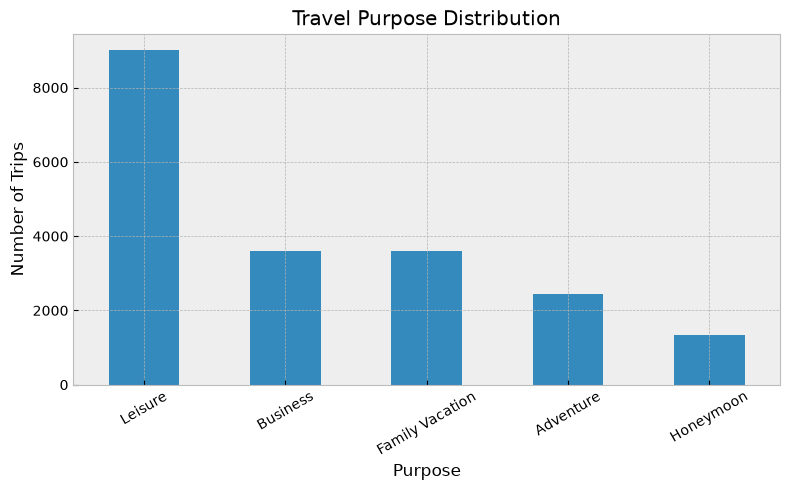

In [ ]:
# Count bookings by travel purpose
purpose = (
    df["Travel_Purpose"]
      .value_counts()
)

plt.figure(figsize=(8,5))

purpose.plot(kind="bar")

plt.title("Travel Purpose Distribution")
plt.xlabel("Purpose")
plt.ylabel("Number of Trips")

plt.xticks(rotation=30)

plt.tight_layout()

plt.savefig("05_Travel_Purpose_Distribution.png")

plt.show()

### 5.6 Satisfaction Rating Distribution

Customer satisfaction ratings are analyzed to understand the overall distribution of traveler experience scores.

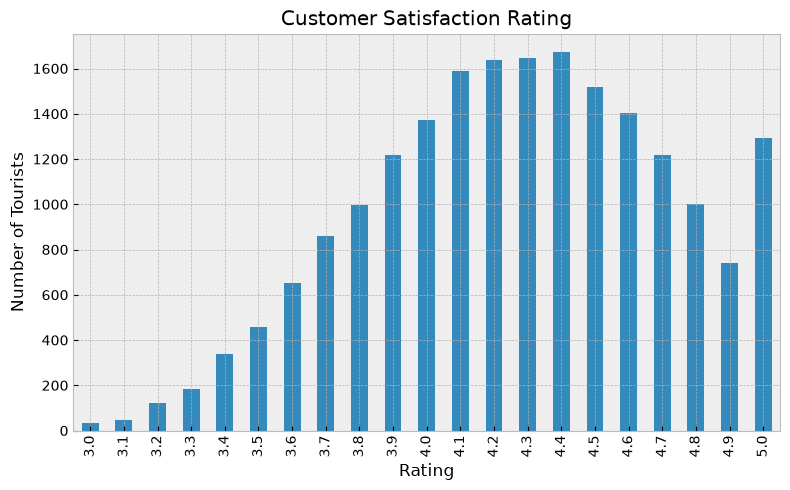

In [ ]:
# Count bookings for each satisfaction rating
plt.figure(figsize=(8,5))

df["Satisfaction_Rating"].value_counts().sort_index().plot(
    kind="bar"
)

plt.title("Customer Satisfaction Rating")
plt.xlabel("Rating")
plt.ylabel("Number of Tourists")

plt.tight_layout()

plt.savefig("06_Satisfaction_Rating.png")

plt.show()

### 5.7 Hotel Category Distribution

The distribution of hotel categories is examined to understand accommodation preferences across travel bookings.

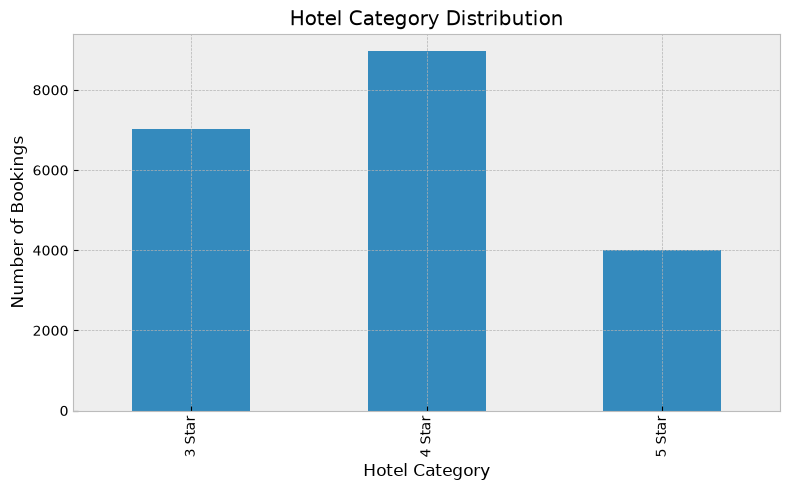

In [ ]:
# Count bookings by hotel category
plt.figure(figsize=(8,5))

df["Hotel_Category"].value_counts().sort_index().plot(
    kind="bar"
)

plt.title("Hotel Category Distribution")
plt.xlabel("Hotel Category")
plt.ylabel("Number of Bookings")

plt.tight_layout()

plt.savefig("07_Hotel_Category_Distribution.png")

plt.show()

### 5.8 Transport Mode Distribution

Transportation preferences are analyzed to identify the most commonly used modes of travel among the bookings.

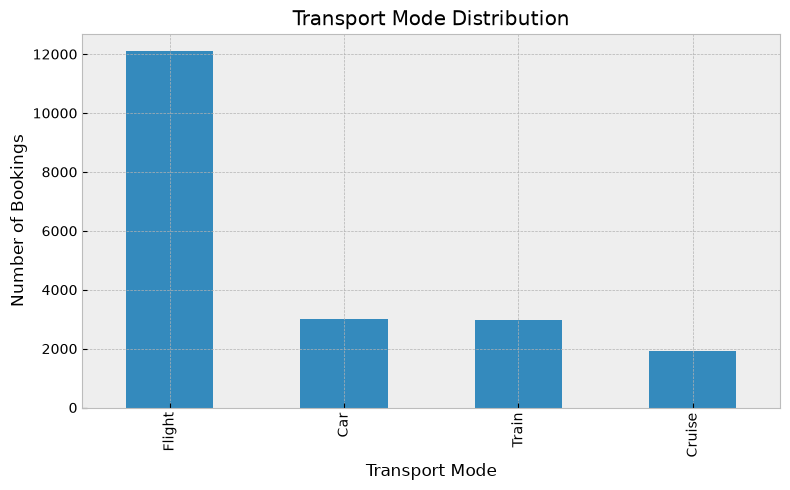

In [ ]:
# Count bookings by transportation mode
plt.figure(figsize=(8,5))

df["Transport_Mode"].value_counts().plot(
    kind="bar"
)

plt.title("Transport Mode Distribution")
plt.xlabel("Transport Mode")
plt.ylabel("Number of Bookings")

plt.tight_layout()

plt.savefig("08_Transport_Mode_Distribution.png")

plt.show()

## 6. Geographic Revenue Analysis

### 6.1 Revenue by Continent

Revenue is aggregated by continent to compare the overall contribution of different geographic regions.

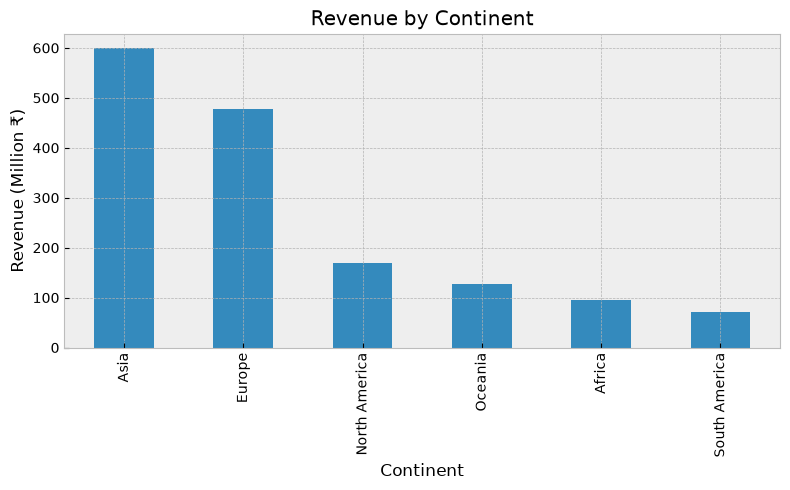

In [ ]:
# Aggregate total trip cost by continent and convert values to million ₹
plt.figure(figsize=(8,5))

(
    df.groupby("Continent")["Total_Trip_Cost"]
    .sum()
    .sort_values(ascending=False)
    .div(1_000_000)
).plot(
    kind="bar"
)

plt.title("Revenue by Continent")
plt.xlabel("Continent")
plt.ylabel("Revenue (Million ₹)")

plt.tight_layout()

plt.savefig("09_Revenue_by_Continent.png")

plt.show()

## 7. Cost Analysis

### 7.1 Trip Cost Distribution

The distribution of total trip costs is examined to understand traveler spending patterns and the range of trip expenditures represented in the dataset.

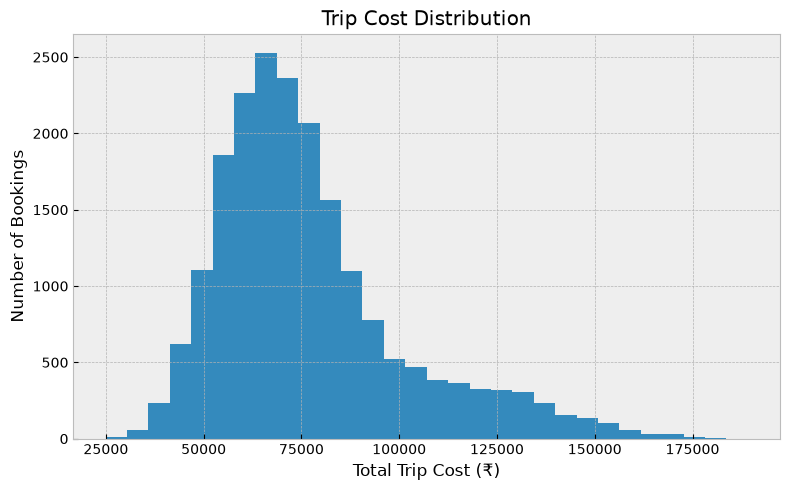

In [ ]:
# Visualize the distribution of total trip costs
plt.figure(figsize=(8,5))

plt.hist(
    df["Total_Trip_Cost"],
    bins=30
)

plt.title("Trip Cost Distribution")
plt.xlabel("Total Trip Cost (₹)")
plt.ylabel("Number of Bookings")

plt.tight_layout()

plt.savefig("10_Trip_Cost_Distribution.png")

plt.show()

## 8. Conclusion

The exploratory analysis provided an overview of booking activity, traveler demographics, destination preferences, travel purposes, accommodation choices, transportation modes, satisfaction levels, geographic contribution, and trip cost distribution across the WanderScape dataset.

The analysis establishes the key patterns and distributions within the dataset and provides a structured foundation for deeper business analysis.

The validated dataset and EDA outputs will be carried forward into the SQL analysis and Power BI dashboard stages of the WanderScape Analytics project.